# 02 · Retention, churn and cohort value

**Questions answered:** how often do customers come back, how should churn be
measured in a non-contractual business, and how much revenue does a cohort retain?

**Grain:** purchase occasion (one customer on one calendar day with at least one
non-reversal order). Invoices are the wrong grain for behaviour: 3,008 customer-days
contain multiple invoices, which would create zero-length intervals.

**Definitions:** [`docs/metrics_dictionary.md`](../docs/metrics_dictionary.md) — churn
(window, lookback, censoring), repeat purchase, cohort retention, revenue retention.


In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "reports" / "tables"
FIGURES = ROOT / "reports" / "figures"
analysis = json.loads((ROOT / "reports" / "analysis.json").read_text())


def gbp(value: float, digits: int = 0) -> str:
    return f"£{value:,.{digits}f}"

## Purchase intervals: how long is a typical gap?

Observed intervals: 27,231 from 4,189 customers
Median 31 d | p75 70 d | p90 147 d | p95 221 d
Share of intervals ≤ 90 days: 80.7%


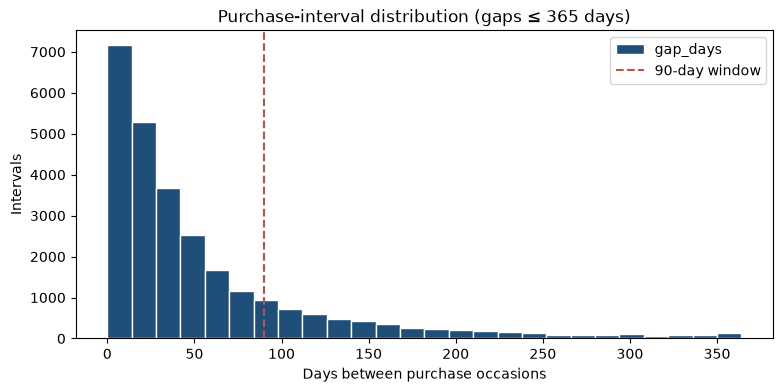

In [2]:
import sys

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from hub.analytics import data, metrics

orders = data.load_table("fact_orders")
intervals = metrics.purchase_intervals(orders)
summary = pd.read_csv(TABLES / "purchase_intervals.csv").iloc[0]

print(
    f"Observed intervals: {int(summary['intervals']):,} "
    f"from {int(summary['customers_with_intervals']):,} customers"
)
print(
    f"Median {summary['median_days']:.0f} d | p75 {summary['p75_days']:.0f} d | "
    f"p90 {summary['p90_days']:.0f} d | p95 {summary['p95_days']:.0f} d"
)
print(f"Share of intervals ≤ 90 days: {(intervals['gap_days'] <= 90).mean():.1%}")

ax = intervals.loc[intervals["gap_days"] <= 365, "gap_days"].plot.hist(
    bins=range(0, 366, 14), color="#1f4e79", edgecolor="white", figsize=(9, 4)
)
ax.axvline(90, color="#c0504d", linestyle="--", label="90-day window")
ax.set_xlabel("Days between purchase occasions")
ax.set_ylabel("Intervals")
ax.set_title("Purchase-interval distribution (gaps ≤ 365 days)")
ax.legend()

The distribution is right-skewed with a strong weekly mode: median 31 days, p75 70,
p90 147. A 90-day window covers 80.7% of observed repeat purchases, which is why
`W = 90` was fixed as the churn horizon. The remaining 19.3% are not noise — they are
the slowly-returning tail, and they are why the churn label means "did not transact
next quarter", not "gone forever".

28.8% of buyers have only one purchase occasion and contribute no interval at all, so
this distribution is itself right-censored and understates the true share of gaps
longer than 90 days.


## Churn definition and sensitivity

,snapshots,eligible_customers,churned_customers,min_rate,max_rate,pooled_rate
window_days,,,,,,
30,22,22165,13636,0.544,0.685,0.615
60,21,33395,16228,0.388,0.632,0.486
90,20,40270,17288,0.313,0.579,0.429
120,19,44317,17604,0.297,0.531,0.397
150,18,46548,17657,0.269,0.497,0.379
180,17,47478,17441,0.244,0.468,0.367


W = 90: 42.9% churn pooled over 20 complete snapshots (40,270 customer-snapshots)


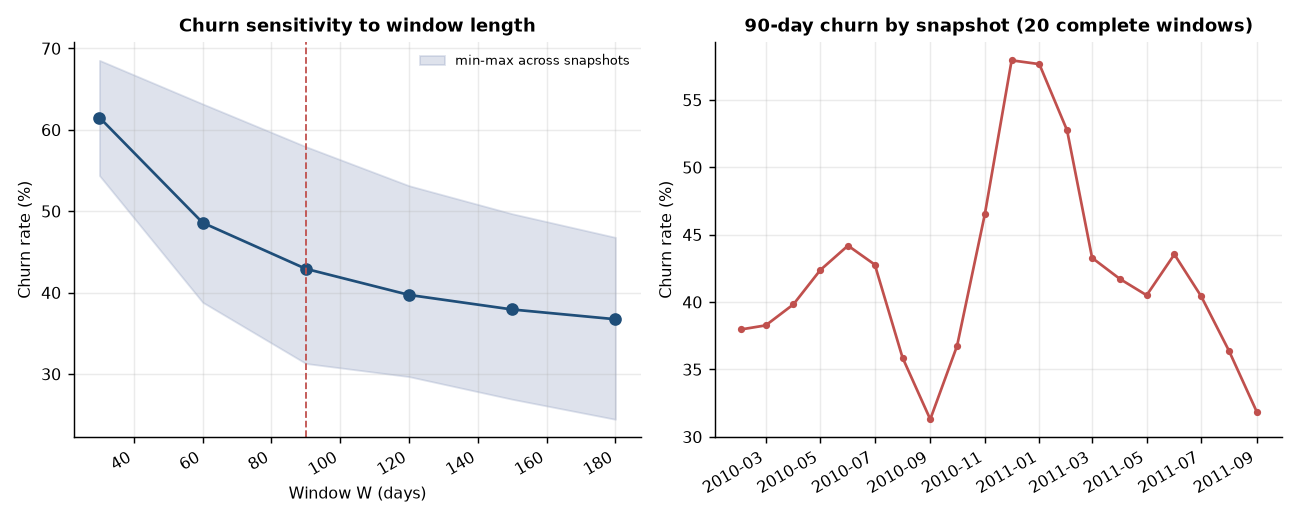

In [3]:
sensitivity = pd.read_csv(TABLES / "churn_window_sensitivity.csv")
display(sensitivity.set_index("window_days").round(3))

churn = analysis["churn"]
sens90 = sensitivity.loc[sensitivity["window_days"] == 90, "pooled_rate"].iloc[0]
assert abs(sens90 - churn["pooled_rate"]) < 1e-12, "SQL snapshots and pandas sensitivity disagree"
print(
    f"W = 90: {churn['pooled_rate']:.1%} churn pooled over "
    f"{churn['snapshots_used']} complete snapshots "
    f"({churn['customer_rows_used']:,} customer-snapshots)"
)
display(Image(filename=str(FIGURES / "churn.png")))

**Definition used everywhere:** a customer active at `t` (at least one purchase occasion
in `[t − 90, t)`) is churned if they have zero purchase occasions in `[t, t + 90)`.
Reversals never count as activity. Snapshots whose forward window runs past the last
observed transaction are excluded, never scored as churn.

The churn rate is 61.5% at 30 days, **42.9% at 90**, and 36.7% at 180: most of the
separation happens by 90 days, then the curve flattens. The level moves by about six
points between 90 and 180, so no decision should hinge on the second decimal of the
window. Snapshot-to-snapshot variation is much larger (31.3%–57.9%) because the
snapshots fall in different seasons, which is exactly why Phase 4 must compare
like-for-like months rather than pooling blindly.

The `assert` above is a reproducibility check: the SQL snapshot table and the pandas
sensitivity function must agree at W = 90. They disagreed before the Phase 3 fix
(invoice grain and reversal activity on one side only); the check now locks that
correction in.


## Cohort retention

Customer-weighted retention (cohorts where the month is observable):
  month  1: 23.4%
  month  3: 24.9%
  month  6: 22.1%
  month 12: 22.7%


,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,,
2009-12-01,1.0,0.353,0.334,0.425,0.380,0.359,0.377,0.342,0.336,0.362,0.422,0.495,0.376
2010-01-01,1.0,0.206,0.311,0.305,0.264,0.300,0.258,0.230,0.279,0.319,0.303,0.172,0.222
2010-02-01,1.0,0.237,0.223,0.290,0.245,0.199,0.191,0.285,0.253,0.274,0.114,0.125,0.152
2010-03-01,1.0,0.190,0.230,0.242,0.233,0.203,0.246,0.302,0.275,0.108,0.115,0.142,0.201
2010-04-01,1.0,0.194,0.194,0.163,0.184,0.224,0.276,0.262,0.105,0.109,0.075,0.139,0.139
2010-05-01,1.0,0.157,0.169,0.173,0.177,0.256,0.213,0.126,0.059,0.083,0.114,0.134,0.154
2010-06-01,1.0,0.174,0.189,0.204,0.230,0.285,0.126,0.089,0.081,0.119,0.107,0.137,0.148
2010-07-01,1.0,0.156,0.183,0.296,0.290,0.140,0.113,0.145,0.145,0.113,0.134,0.145,0.134
2010-08-01,1.0,0.204,0.296,0.321,0.173,0.117,0.099,0.123,0.136,0.130,0.130,0.123,0.154


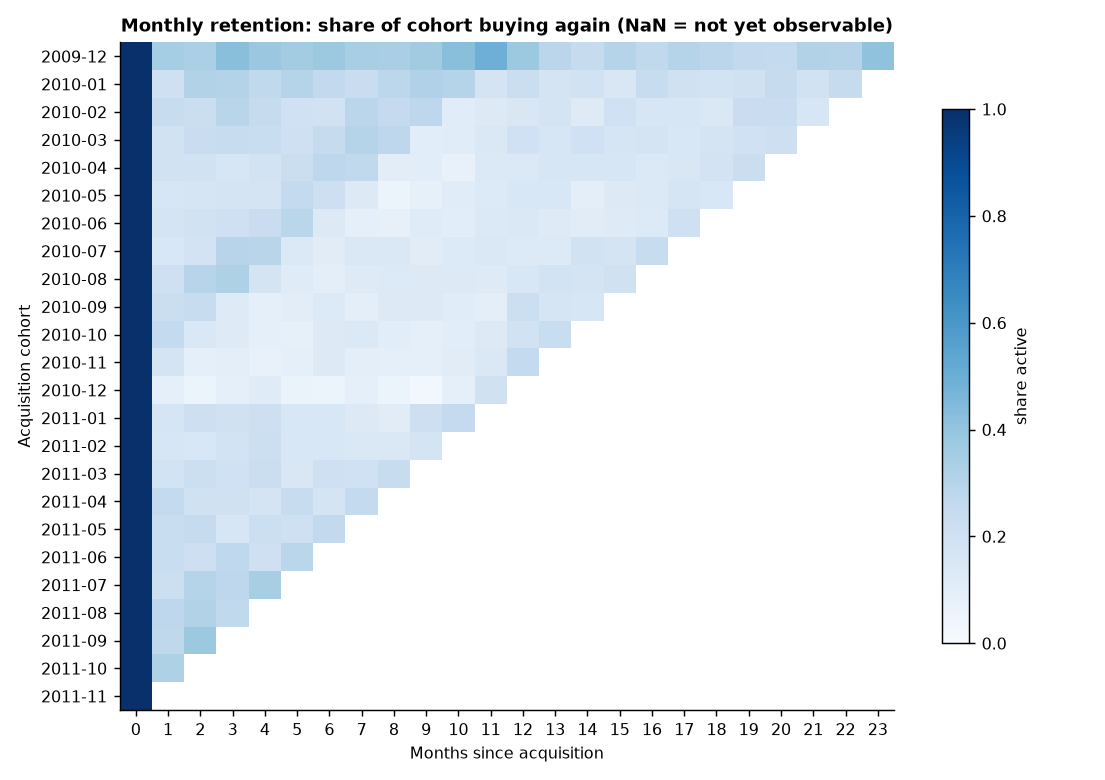

In [4]:
retention = pd.read_csv(TABLES / "cohort_retention.csv", index_col=0)
retention.index = pd.to_datetime(retention.index)
retention.columns = [int(column) for column in retention.columns]
sizes = pd.read_csv(TABLES / "cohort_sizes.csv", parse_dates=["cohort_month"])
sizes = sizes.set_index("cohort_month")["customers"]

weighted = {}
for month in (1, 3, 6, 12):
    observed = retention[month].dropna()
    weights = sizes.reindex(observed.index)
    weighted[month] = (observed * weights).sum() / weights.sum()

print("Customer-weighted retention (cohorts where the month is observable):")
for month, value in weighted.items():
    print(f"  month {month:>2}: {value:.1%}")
display(retention.iloc[:10, :13].round(3))
display(Image(filename=str(FIGURES / "cohort_retention.png")))

Retention is **front-loaded and then flat**: 23.4% of a cohort is still buying in
month 1, and 22.7% is still buying in month 12. Almost the entire loss happens before
the first repeat month; after that the surviving base is stable. The 2009-12 cohort is
left-censored (we only see its first month onward), which is flagged, not smoothed away.
The December 2010 cohort of 76 is genuinely small because most December shoppers were
already customers; cohort size is not a data error.


## Revenue retention and cumulative value

Month  3 cumulative revenue/customer — median £672, best cohort £1,772


Month  6 cumulative revenue/customer — median £937, best cohort £2,676
Month 12 cumulative revenue/customer — median £1,427, best cohort £5,071


,0,1,2,3,4,5,6,7,8
cohort_month,,,,,,,,,
2009-12-01,1.0,0.560,0.428,0.561,0.441,0.417,0.443,0.453,0.490
2010-01-01,1.0,0.241,0.314,0.349,0.353,0.372,0.304,0.286,0.368
2010-02-01,1.0,0.193,0.315,0.311,0.253,0.235,0.225,0.305,0.314
2010-03-01,1.0,0.258,0.247,0.284,0.257,0.281,0.336,0.424,0.396
2010-04-01,1.0,0.143,0.165,0.221,0.180,0.247,0.285,0.257,0.081
2010-05-01,1.0,0.119,0.127,0.115,0.151,0.283,0.210,0.080,0.041
2010-06-01,1.0,0.098,0.183,0.208,0.284,0.390,0.126,0.141,0.195
2010-07-01,1.0,0.107,0.188,0.344,0.394,0.123,0.124,0.146,0.140


,0,1,2,3,4,5,6,7,8
cohort_month,,,,,,,,,
2009-12-01,695.0,1085.0,1382.0,1772.0,2078.0,2368.0,2676.0,2992.0,3332.0
2010-01-01,416.0,516.0,647.0,792.0,939.0,1094.0,1221.0,1339.0,1492.0
2010-02-01,440.0,525.0,664.0,801.0,913.0,1016.0,1115.0,1249.0,1388.0
2010-03-01,427.0,537.0,643.0,764.0,873.0,993.0,1136.0,1317.0,1486.0
2010-04-01,417.0,476.0,544.0,636.0,711.0,814.0,933.0,1040.0,1073.0
2010-05-01,429.0,480.0,534.0,584.0,648.0,769.0,859.0,894.0,911.0
2010-06-01,451.0,495.0,578.0,672.0,800.0,976.0,1032.0,1096.0,1184.0
2010-07-01,383.0,424.0,496.0,628.0,779.0,827.0,874.0,930.0,984.0


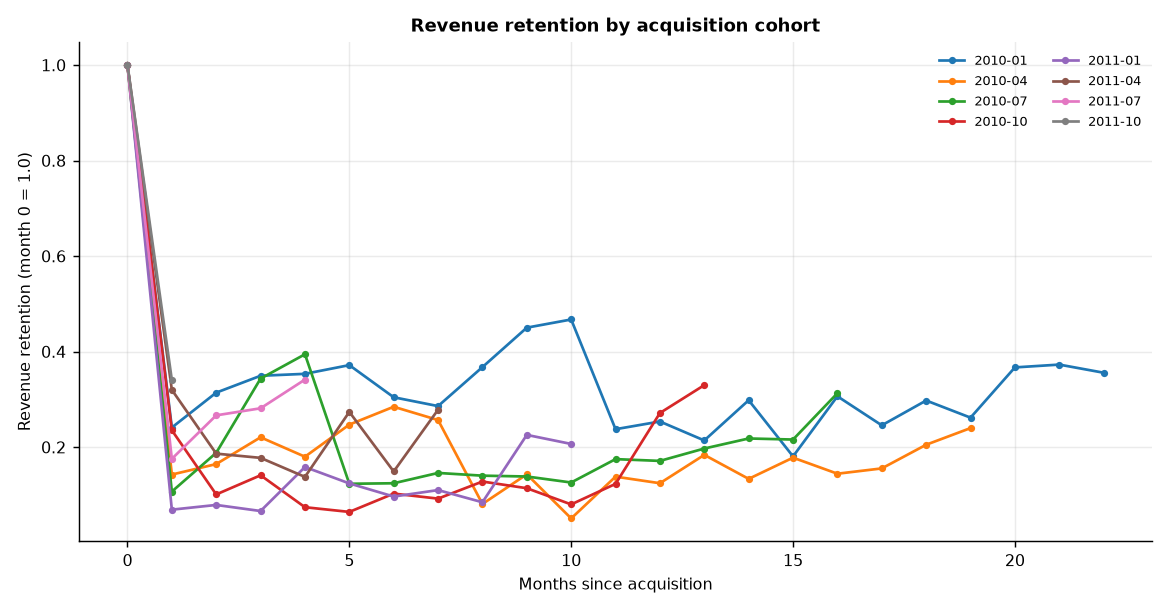

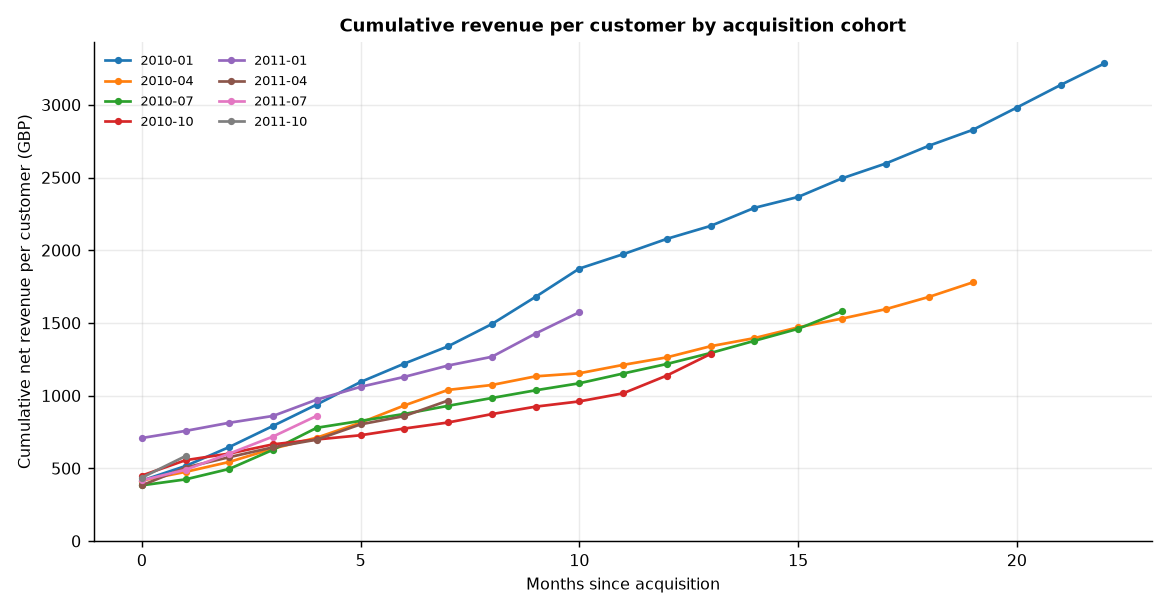

In [5]:
revenue_retention = pd.read_csv(TABLES / "cohort_revenue_retention.csv", index_col=0)
revenue_retention.index = pd.to_datetime(revenue_retention.index)
revenue_retention.columns = [int(column) for column in revenue_retention.columns]
cumulative = pd.read_csv(TABLES / "cohort_cumulative_revenue_per_customer.csv", index_col=0)
cumulative.index = pd.to_datetime(cumulative.index)
cumulative.columns = [int(column) for column in cumulative.columns]

for month in (3, 6, 12):
    observed = cumulative[month].dropna().sort_values()
    print(
        f"Month {month:>2} cumulative revenue/customer — "
        f"median {gbp(observed.median())}, best cohort {gbp(observed.max())}"
    )

display(revenue_retention.iloc[:8, :9].round(3))
display(cumulative.iloc[:8, :9].round(0))
display(Image(filename=str(FIGURES / "cohort_revenue_retention.png")))
display(Image(filename=str(FIGURES / "cohort_cumulative_revenue.png")))

Revenue retention is noisier than logo retention because a retained customer can spend
much less. The cumulative curve is the cleanest value view: the median cohort is worth
about £1,427 per customer by month 12, while the best cohort (2009-12) reaches £5,071.
The spread is driven by account size, not by a different retention rate — the 2009-12
cohort retains at a similar rate but spends far more, which is the wholesale tail from
notebook 01 showing up again.


## So what?

1. **42.9% of active customers will not buy in the next 90 days.** That is the number
   the retention programme has to move, and it is stable enough to act on: 48.6% at 60
   days and 39.7% at 120, so the 90-day choice does not change the priority.
2. **The leak is in month 0, not month 12.** Retention is 23.4% in month 1 and 22.7%
   in month 12. Onboarding and the first repeat purchase are the only meaningful
   levers; later-life retention interventions address a base that has already stabilized.
3. **28.8% of buyers never return.** Converting even a tenth of the 1,692 one-time
   buyers into a second purchase is worth more than a broad win-back campaign, because
   every second purchase is the entry ticket to the flat 23% retained base.
4. **Value per retained customer is £1,427 at 12 months (median cohort).** Any
   retention programme that costs more than a few tens of pounds per saved customer is
   buying negative margin at typical order values.
5. **Seasonality contaminates raw churn.** Snapshot churn ranges 31.3%–57.9%; Phase 4
   must compare year-over-year months or model the seasonal effect, not pool snapshots.


## Limitations

- Churn is a definition, not an observed event; there is no cancellation record.
- Right-censored snapshots are excluded from every rate; 84.4% of active
  customer-snapshots at W = 90 have a complete label window, and 20 of 23 snapshot dates
  survive. Ignoring this was the source of the earlier, wrong sensitivity figures.
- 61 of 5,942 identified customers appear only on cancellation invoices and have no
  purchase occasion, so they are outside the buyer base entirely.
- Cohort revenue retention uses month 0 = 100% by construction, so it shows shape, not
  absolute value; use the cumulative table for value.
